# Within-simulation prediction and cross-simulation transfer

Good performance in one simulation does not guarantee generalization across another.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

RMSE and signed bias refer to log10 mass in dex. Bias is posterior median minus truth,
averaged over pairs. R² depends on the variance of the evaluated target population;
it is not directly comparable across differently selected populations.

First read the early block grid, then the final six. The block transfer table uses
the 231 held-out TNG rows; some older diagnostics used all 1530 TNG pairs.


,block,domain,subset,posterior_draws,n,rmse,r2,bias,...,target_sd,rmse_lo,rmse_hi,r2_lo,r2_hi,bias_lo,bias_hi,n_components_pooled
0,core_dynamics,flamingo,full,200,21409,0.156118,0.755732,-0.000148,...,0.315877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,core_dynamics,flamingo,same_host,200,9461,0.163523,0.770652,-0.001617,...,0.341454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,core_dynamics,flamingo,diff_host,200,11929,0.131870,0.726123,0.003988,...,0.251981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,core_chemistry,flamingo,full,200,21409,0.154804,0.759826,0.002057,...,0.315877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,core_chemistry,flamingo,same_host,200,9461,0.162108,0.774604,0.000585,...,0.341454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,core_chemistry,flamingo,diff_host,200,11929,0.131830,0.726291,0.007811,...,0.251981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,core_morphology,flamingo,full,200,21409,0.088467,0.921562,0.001755,...,0.315877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,core_morphology,flamingo,same_host,200,9461,0.083146,0.940705,0.001192,...,0.341454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,core_morphology,flamingo,diff_host,200,11929,0.079379,0.900763,-0.001264,...,0.251981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,core_photometry,flamingo,full,200,21409,0.144303,0.791305,-0.004539,...,0.315877,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,block,within_n,transfer_n,within_rmse,within_r2,within_bias,transfer_rmse,transfer_r2,...,r2_drop,bias_change,rmse_lower95,rmse_upper95,r2_lower95,r2_upper95,bias_lower95,bias_upper95
0,core_dynamics,21409,231,0.156118,0.755732,-0.000148,0.197206,0.685332,...,0.070399,-0.106177,0.171144,0.224810,0.612281,0.745982,-0.128143,-0.084481
1,core_chemistry,21409,231,0.154804,0.759826,0.002057,0.202016,0.669796,...,0.090030,-0.109099,0.173457,0.232473,0.588634,0.736152,-0.129940,-0.084795
2,core_morphology,21409,231,0.088467,0.921562,0.001755,0.219023,0.611857,...,0.309705,-0.197649,0.206475,0.232105,0.504945,0.686711,-0.208998,-0.183278
3,core_photometry,21409,231,0.144303,0.791305,-0.004539,0.194886,0.692694,...,0.098611,-0.106143,0.170384,0.221108,0.623793,0.748937,-0.131520,-0.089720
4,all_features,21409,231,0.085741,0.926322,0.001339,0.233641,0.558317,...,0.368004,-0.209484,0.220473,0.247163,0.435266,0.646244,-0.222154,-0.194372


,model_A,model_B,metric,difference_B_minus_A,lower95,upper95,repeats
0,core_dynamics,core_chemistry,rmse,0.004810,-0.000775,0.009945,5000
1,core_dynamics,core_chemistry,bias,-0.000716,-0.005081,0.003715,5000
2,core_dynamics,core_morphology,rmse,0.021817,-0.006907,0.049251,5000
3,core_dynamics,core_morphology,bias,-0.089568,-0.111666,-0.068038,5000
4,core_dynamics,core_photometry,rmse,-0.002320,-0.010467,0.005827,5000
5,core_dynamics,core_photometry,bias,-0.004356,-0.014131,0.004779,5000
6,core_dynamics,all_features,rmse,0.036435,0.005774,0.066162,5000
7,core_dynamics,all_features,bias,-0.101819,-0.127030,-0.077236,5000


,model,domain,n,rmse,bias,r2,coverage68,coverage95
0,combined_dynamics,flamingo,21409,0.262693,0.087176,0.308391,0.747256,0.957588
1,combined_dynamics,tng,231,0.318798,-0.072471,0.177680,0.731602,0.917749
4,combined_stellar_sum,flamingo,21409,0.188727,0.094936,0.643029,0.712831,0.949787
5,combined_stellar_sum,tng,231,0.208268,-0.121711,0.649043,0.640693,0.900433
8,flamingo_dynamics,flamingo,21409,0.234264,-0.003195,0.449986,0.728385,0.940539
9,flamingo_dynamics,tng,231,0.365471,-0.155426,-0.080725,0.649351,0.852814
12,flamingo_stellar_sum,flamingo,21409,0.131649,-0.002404,0.826302,0.696343,0.947125
13,flamingo_stellar_sum,tng,231,0.360156,-0.316399,-0.049524,0.199134,0.497835
16,tng_dynamics,flamingo,21409,0.334127,0.194850,-0.118887,0.604559,0.940212
17,tng_dynamics,tng,231,0.303766,-0.005578,0.253399,0.718615,0.939394


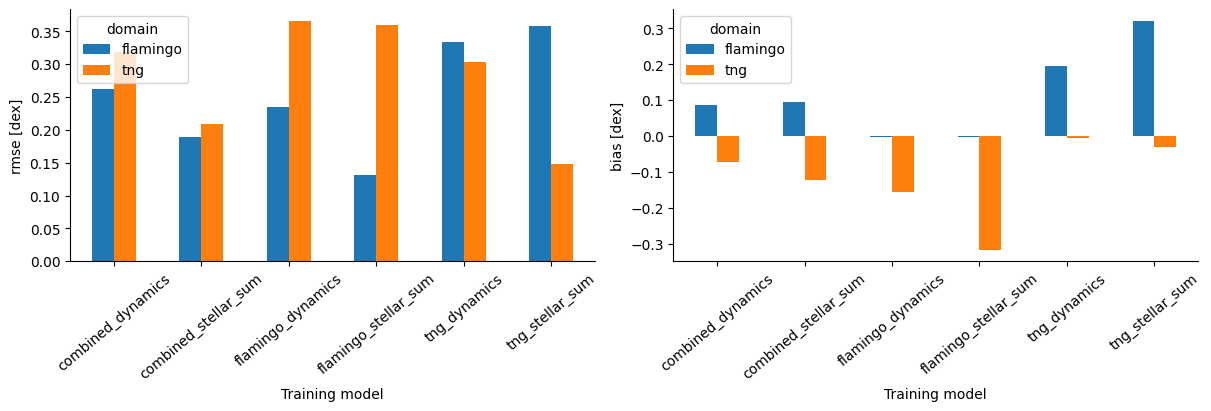

In [2]:
display(table('within/block_median_metrics_and_tng_intervals.csv'))
display(table('cross/block_transfer_test.csv'))
display(table('cross/block_paired_contrasts.csv'))
metrics=table('final_six/six_model_metrics.csv')
pooled=metrics.query("subset == 'pooled'")
display(pooled[['model','domain','n','rmse','bias','r2','coverage68','coverage95']])
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,metric in zip(axes,['rmse','bias']):
    pooled.pivot(index='model',columns='domain',values=metric).plot.bar(ax=ax)
    ax.set(ylabel=metric+' [dex]',xlabel='Training model');ax.tick_params(axis='x',rotation=40)
plt.show()

Adding stellar sum improves in-domain RMSE, but transfer develops a large directional
bias and low credible-interval coverage. Balanced combined training reduces some
pooled transfer errors but retains opposite biases on the two domains.

### Paired uncertainty and host strata

Differences below are model B minus model A on the same rows. The interval centre
is a bootstrap median, which can differ from the observed difference of headline metrics.
The final comparisons use 2000 connected-component resamples conditional on the
fitted models and saved draws. They do not include NPE retraining or cosmic variance.


In [3]:
intervals=table('cross/final_six_paired_intervals_with_point_estimates.csv')
display(intervals.query("subset == 'pooled' and metric == 'rmse'"))
display(metrics.query("domain == 'tng' and subset == 'different_host'")[
    ['model','n','rmse','bias','r2','coverage68','coverage95']])
assert (metrics.query("domain == 'tng' and subset == 'different_host'").n == 48).all()

,subset,metric,median,lower95,upper95,repeats,model_A,model_B,domain,observed_difference_B_minus_A
5,pooled,rmse,0.028452,0.026302,0.030529,2000,flamingo_dynamics,combined_dynamics,flamingo,0.028429
14,pooled,rmse,-0.046434,-0.068083,-0.026644,2000,flamingo_dynamics,combined_dynamics,tng,-0.046673
23,pooled,rmse,-0.071424,-0.073009,-0.069723,2000,tng_dynamics,combined_dynamics,flamingo,-0.071434
32,pooled,rmse,0.015037,0.001960,0.027591,2000,tng_dynamics,combined_dynamics,tng,0.015032
41,pooled,rmse,0.057076,0.055165,0.059098,2000,flamingo_stellar_sum,combined_stellar_sum,flamingo,0.057079
50,pooled,rmse,-0.151631,-0.165474,-0.136847,2000,flamingo_stellar_sum,combined_stellar_sum,tng,-0.151889
59,pooled,rmse,-0.169060,-0.170710,-0.167332,2000,tng_stellar_sum,combined_stellar_sum,flamingo,-0.169063
68,pooled,rmse,0.059507,0.043478,0.075899,2000,tng_stellar_sum,combined_stellar_sum,tng,0.059608
77,pooled,rmse,-0.102547,-0.105749,-0.099481,2000,flamingo_dynamics,flamingo_stellar_sum,flamingo,-0.102615
86,pooled,rmse,-0.004300,-0.049687,0.040780,2000,flamingo_dynamics,flamingo_stellar_sum,tng,-0.005314


,model,n,rmse,bias,r2,coverage68,coverage95
3,combined_dynamics,48,0.149135,-0.024381,0.440766,0.854167,0.979167
7,combined_stellar_sum,48,0.205467,-0.180222,-0.061487,0.437500,0.895833
11,flamingo_dynamics,48,0.163424,-0.081030,0.328473,0.770833,0.979167
15,flamingo_stellar_sum,48,0.367104,-0.352973,-2.388511,0.000000,0.125000
19,tng_dynamics,48,0.162530,0.053186,0.335797,0.770833,1.000000
23,tng_stellar_sum,48,0.132000,-0.083799,0.561891,0.708333,0.895833


The different-host stratum matters for the Local Group: pooled improvement can hide
worse performance on those 48 held-out pairs. Same-host and different-host targets
also have different physical meanings. See the
[final-six workflow](../research/notebooks/original/final_six_model_experiment.ipynb)
and [evaluation helpers](../research/src/lg_npe/evaluation.py) for the calculation.


[Previous](03_npe_and_experimental_design.ipynb) · [Next](05_calibration.ipynb) · [Repository map](../README.md)
